# DATA INTENSIVE SYSTEMS IN BIOMEDICINE

## Opis projektu:

Celem niniejszego projektu jest przeprowadzenie kompleksowej analizy inżynierskiej zbioru danych dotyczącego wskaźników zdrowotnych powiązanych z ryzykiem zachorowania na cukrzycę. Projekt został zrealizowany w oparciu o architekturę Apache Spark, co zapewnia wysoką wydajność obliczeniową oraz skalowalność przetwarzania danych.

---
## Wymogi: 
* ``Przeprowadź czyszczenie danych (jesli jest to wymagane lub nie – w obu przypadkach uzasadnij), zweryfikuj ilość pustych wartości i czy mają jakiś wpływ na analizę ``
* ``Przedstaw klasyfikację danych ``
* ``Wykorzystaj MLlib do predykcji ``
* ``Uwzględnij wizualizację danych za pomocą bibliotek pandas lub matplotlib.``
* ``Skorzystaj z paradygmatu MapReduce oraz funkcji lambda. ``
---

## Wczytanie danych za pomocą spark i wyświetlenie 10 pierwszych wierszy

In [2]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Diabetes Analysis") \
    .getOrCreate()

DATA_PATH = "/app/data/diabetes_health_indicators.csv"

df = spark.read.csv(
    DATA_PATH,
    header=True,
    inferSchema=True
)

df.show(10, truncate=False)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/06/15 14:39:45 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


+------------+------+--------+---------+----+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+----+---------+------+
|Diabetes_012|HighBP|HighChol|CholCheck|BMI |Smoker|Stroke|HeartDiseaseorAttack|PhysActivity|Fruits|Veggies|HvyAlcoholConsump|AnyHealthcare|NoDocbcCost|GenHlth|MentHlth|PhysHlth|DiffWalk|Sex|Age |Education|Income|
+------------+------+--------+---------+----+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+----+---------+------+
|0.0         |1.0   |1.0     |1.0      |40.0|1.0   |0.0   |0.0                 |0.0         |0.0   |1.0    |0.0              |1.0          |0.0        |5.0    |18.0    |15.0    |1.0     |0.0|9.0 |4.0      |3.0   |
|0.0         |0.0   |0.0     |0.0      |25.0|1.0   |0.0   |0.0                 |1.0         |0.0   |0.0    |0.0              |0.0          |1.0 

In [3]:
print("-" * 15 + "Informacje o Strukturze bazy danych" + "-" * 15)
print(f'Całkowita ilość wierszy: {df.count()}')
print(f'Całkowita ilość kolumn: {len(df.columns)}')
print(f'Nazwy kolumn: {df.columns}')
print(65 * "-")

---------------Informacje o Strukturze bazy danych---------------
Całkowita ilość wierszy: 253680
Całkowita ilość kolumn: 22
Nazwy kolumn: ['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
-----------------------------------------------------------------


## Sprawdzenie czy występują puste wiersze

In [4]:
from pyspark.sql.functions import col, count, when

# Zliczanie brakujących (null) wartości w każdej kolumnie
missing_values = df.select([
    count(when(col(c).isNull(), c)).alias(c) 
    for c in df.columns
])

missing_values.show(truncate=False)

+------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+---+---------+------+
|Diabetes_012|HighBP|HighChol|CholCheck|BMI|Smoker|Stroke|HeartDiseaseorAttack|PhysActivity|Fruits|Veggies|HvyAlcoholConsump|AnyHealthcare|NoDocbcCost|GenHlth|MentHlth|PhysHlth|DiffWalk|Sex|Age|Education|Income|
+------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+---+---------+------+
|0           |0     |0       |0        |0  |0     |0     |0                   |0           |0     |0      |0                |0            |0          |0      |0       |0       |0       |0  |0  |0        |0     |
+------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-

Dla każdej kolumny sprawdzono liczbę wartości NULL. Wyniki pokazują, że:

- żadna kolumna nie zawiera brakujących danych,
- wszystkie wartości wynoszą 0 (brak braków).

W związku z tym zbiór danych nie wymagał procesu czyszczenia. Brak brakujących danych oznacza, że dane są kompletne i mogą zostać bezpośrednio wykorzystane do dalszej analizy oraz budowy modelu ML.

---

## Przedstawienie klasyfikacji danych

In [5]:
df.printSchema()

root
 |-- Diabetes_012: double (nullable = true)
 |-- HighBP: double (nullable = true)
 |-- HighChol: double (nullable = true)
 |-- CholCheck: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- Smoker: double (nullable = true)
 |-- Stroke: double (nullable = true)
 |-- HeartDiseaseorAttack: double (nullable = true)
 |-- PhysActivity: double (nullable = true)
 |-- Fruits: double (nullable = true)
 |-- Veggies: double (nullable = true)
 |-- HvyAlcoholConsump: double (nullable = true)
 |-- AnyHealthcare: double (nullable = true)
 |-- NoDocbcCost: double (nullable = true)
 |-- GenHlth: double (nullable = true)
 |-- MentHlth: double (nullable = true)
 |-- PhysHlth: double (nullable = true)
 |-- DiffWalk: double (nullable = true)
 |-- Sex: double (nullable = true)
 |-- Age: double (nullable = true)
 |-- Education: double (nullable = true)
 |-- Income: double (nullable = true)



### Opis struktury danych

Dzięki zastosowaniu funkcji `printSchema()` możliwe jest wyświetlenie struktury analizowanej bazy danych. Analizując wynik funkcji można zauważyć, że:
- wszystkie kolumny w zbiorze danych są typu numerycznego (`double`),
- każda kolumna dopuszcza wartości NULL (nullable = true), jednak wcześniejsza analiza wykazała brak brakujących danych.

In [6]:
df.describe().show(truncate=False)

26/06/15 14:39:57 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 9:>                                                          (0 + 4) / 4]

+-------+-------------------+-------------------+-------------------+------------------+------------------+-------------------+-------------------+--------------------+------------------+------------------+------------------+-------------------+-------------------+-------------------+------------------+------------------+------------------+-------------------+------------------+-----------------+------------------+------------------+
|summary|Diabetes_012       |HighBP             |HighChol           |CholCheck         |BMI               |Smoker             |Stroke             |HeartDiseaseorAttack|PhysActivity      |Fruits            |Veggies           |HvyAlcoholConsump  |AnyHealthcare      |NoDocbcCost        |GenHlth           |MentHlth          |PhysHlth          |DiffWalk           |Sex               |Age              |Education         |Income            |
+-------+-------------------+-------------------+-------------------+------------------+------------------+-----------------

### Podział zmiennych

Na podstawie analizy zbioru danych można wyróżnić kilka typów zmiennych, które się w nim znajdują:

| Typ zmiennej | Nazwa zmiennej | Opis | Wartości / Zakres |
| :--- | :--- | :--- | :--- |
| **Docelowa** | `Diabetes_012` | Status cukrzycy | 0 – brak, 1 – stan przedcukrzycowy, 2 – cukrzyca |
| **Binarna** | `HighBP` | Nadciśnienie | 0 – brak, 1 – występuje |
| **Binarna** | `HighChol` | Wysoki cholesterol | 0 – brak, 1 – występuje |
| **Binarna** | `CholCheck` | Badanie cholesterolu w ciągu ostatnich 5 lat | 0 – brak, 1 – tak |
| **Binarna** | `Smoker` | Czy kiedykolwiek wypalono ≥100 papierosów | 0 – nie, 1 – tak |
| **Binarna** | `Stroke` | Przebyty udar | 0 – nie, 1 – tak |
| **Binarna** | `HeartDiseaseorAttack` | Choroba serca lub zawał | 0 – nie, 1 – tak |
| **Binarna** | `PhysActivity` | Aktywność fizyczna w ostatnich 30 dniach | 0 – brak, 1 – tak |
| **Binarna** | `Fruits` | Spożycie owoców ≥1 raz dziennie | 0 – nie, 1 – tak |
| **Binarna** | `Veggies` | Spożycie warzyw ≥1 raz dziennie | 0 – nie, 1 – tak |
| **Binarna** | `HvyAlcoholConsump` | Nadmierne spożycie alkoholu | 0 – nie, 1 – tak |
| **Binarna** | `AnyHealthcare` | Dostęp do opieki zdrowotnej | 0 – brak, 1 – tak |
| **Binarna** | `NoDocbcCost` | Brak wizyty lekarskiej z powodu kosztów | 0 – nie, 1 – tak |
| **Binarna** | `DiffWalk` | Trudności w chodzeniu lub wchodzeniu po schodach | 0 – brak, 1 – tak |
| **Binarna** | `Sex` | Płeć | 0 – female, 1 – male |
| **Ciągła** | `BMI` | Wskaźnik masy ciała | Zakres: 12 – 98 |
| **Kategoryczna** | `GenHlth` | Ogólny stan zdrowia | 1 (excellent) do 5 (poor) |
| **Kategoryczna** | `MentHlth` | Liczba dni gorszego samopoczucia psychicznego | Zakres: 0 – 30 |
| **Kategoryczna** | `Age` | Kategoria wieku | Skala: 1 – 13 |
| **Kategoryczna** | `PhysHlth` | Liczba dni niezdrowego trybu życia | Zakres: 0 – 30 |
| **Kategoryczna** | `Education` | Poziom edukacji | 1 (brak/przedszkole) do 6 (wyższe) |
| **Kategoryczna** | `Income` | Poziom dochodu | 1 (< $10,000) do 8 (≥ $75,000) |

Dla zmiennych **binarnych i kategorycznych** zastosowano analizę rozkładu wartości. Żeby zapoznać się z rozkładem tego typu danych.

In [7]:
categorical_columns = [c for c in df.columns if c != "BMI"]

total_count = df.count()

for col_name in categorical_columns:
    print(f"\nKolumna: {col_name}")
    
    df.groupBy(col_name) \
      .count() \
      .orderBy(col_name) \
      .show(truncate=False)


Kolumna: Diabetes_012
+------------+------+
|Diabetes_012|count |
+------------+------+
|0.0         |213703|
|1.0         |4631  |
|2.0         |35346 |
+------------+------+


Kolumna: HighBP
+------+------+
|HighBP|count |
+------+------+
|0.0   |144851|
|1.0   |108829|
+------+------+


Kolumna: HighChol
+--------+------+
|HighChol|count |
+--------+------+
|0.0     |146089|
|1.0     |107591|
+--------+------+


Kolumna: CholCheck
+---------+------+
|CholCheck|count |
+---------+------+
|0.0      |9470  |
|1.0      |244210|
+---------+------+


Kolumna: Smoker
+------+------+
|Smoker|count |
+------+------+
|0.0   |141257|
|1.0   |112423|
+------+------+


Kolumna: Stroke
+------+------+
|Stroke|count |
+------+------+
|0.0   |243388|
|1.0   |10292 |
+------+------+


Kolumna: HeartDiseaseorAttack
+--------------------+------+
|HeartDiseaseorAttack|count |
+--------------------+------+
|0.0                 |229787|
|1.0                 |23893 |
+--------------------+------+


Kolu

Po określeniu rozkładu cech nakreślona została macież korelacji aby określic, które czynniki mają największy związek z ryzykiem wystapienia cukrzycy.

26/06/15 14:40:13 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
                                                                                

Text(0.5, 1.0, 'Macierz korelacji wszystkich cech')

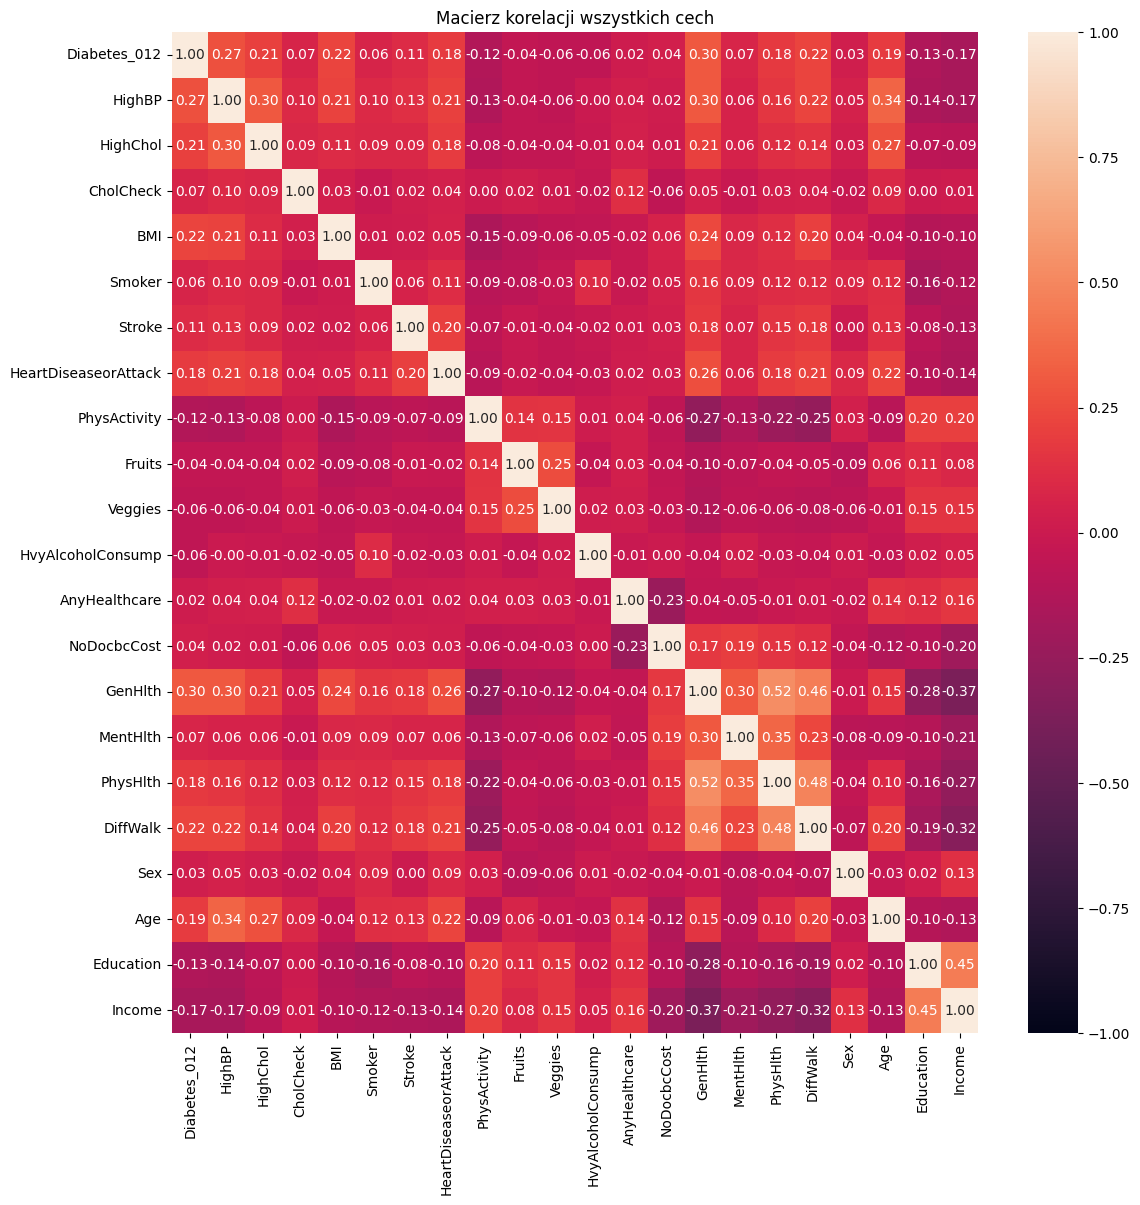

In [8]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

all_cols = df.columns

assembler = VectorAssembler(inputCols=all_cols, outputCol="features")
df_vectorized = assembler.transform(df)

matrix = Correlation.corr(df_vectorized, "features").head()[0]
corr_df = pd.DataFrame(matrix.toArray(), index=all_cols, columns=all_cols)

plt.figure(figsize=(13, 13))
sns.heatmap(corr_df, annot=True, vmin=-1, vmax=1, fmt=".2f")
plt.title("Macierz korelacji wszystkich cech")

## Binaryzacja zmiennej docelowej

Zmienna `Diabetes_012` przyjmuje wartości 0 (brak), 1 (stan przedcukrzycowy) i 2 (cukrzyca). Ze względu na silną **nierównowagę klas** (klasa 1 to zaledwie ~1.8% danych), przekształcamy problem do klasyfikacji binarnej:
- `0` → brak cukrzycy
- `1` → cukrzyca lub stan przedcukrzycowy (klasy 1 i 2 łącznie)

Do transformacji używamy **funkcji lambda** oraz paradygmatu **MapReduce**.

In [18]:
from pyspark.sql.functions import col, udf
from pyspark.sql.types import IntegerType

# Lambda: 0 -> 0 (zdrowy), 1 lub 2 -> 1 (chory/zagrozony)
binarize = udf(lambda x: 0 if x == 0.0 else 1, IntegerType())

df_binary = df.withColumn("label", binarize(col("Diabetes_012")))

print("Rozklad zmiennej label (0 = brak, 1 = cukrzyca/przedcukrzycowy):")
df_binary.groupBy("label").count().orderBy("label").show()

total = df_binary.count()
counts = {row["label"]: row["count"] for row in df_binary.groupBy("label").count().collect()}
for label, cnt in sorted(counts.items()):
    print(f"  Klasa {label}: {cnt} ({cnt/total*100:.1f}%)")

Rozklad zmiennej label (0 = brak, 1 = cukrzyca/przedcukrzycowy):
+-----+------+
|label| count|
+-----+------+
|    0|213703|
|    1| 39977|
+-----+------+

  Klasa 0: 213703 (84.2%)
  Klasa 1: 39977 (15.8%)


## MapReduce — analiza wskaznika cukrzycy per cecha

Przy uzyciu paradygmatu MapReduce obliczamy odsetek chorych dla kazdej wartosci wybranych cech binarnych. Kazdy wiersz jest **mapowany** na pare `(wartosc_cechy, label)`, a nastepnie **redukowany** do sredniego wskaznika cukrzycy.

In [10]:
# MapReduce: odsetek chorych per wartosc cechy binarnej
binary_features = ["HighBP", "HighChol", "Smoker", "Stroke",
                   "HeartDiseaseorAttack", "PhysActivity", "DiffWalk"]

print(f"{'Cecha':<25} {'Wartosc':<10} {'Lacznie':<10} {'Chorych':<10} {'Odsetek %':<10}")
print("-" * 65)

for feature in binary_features:
    # MAP: (wartosc_cechy, label) -> 1  |  REDUCE: sumowanie
    rdd_mapped = df_binary.select(feature, "label").rdd \
        .map(lambda row: ((row[0], row[1]), 1))

    rdd_reduced = rdd_mapped.reduceByKey(lambda a, b: a + b)

    result = rdd_reduced.collect()

    totals = {}
    sick = {}
    for (val, lbl), cnt in result:
        totals[val] = totals.get(val, 0) + cnt
        if lbl == 1:
            sick[val] = sick.get(val, 0) + cnt

    for val in sorted(totals.keys()):
        s = sick.get(val, 0)
        pct = s / totals[val] * 100
        print(f"{feature:<25} {val:<10.0f} {totals[val]:<10} {s:<10} {pct:<10.1f}")
print()

Cecha                     Wartosc    Lacznie    Chorych    Odsetek % 
-----------------------------------------------------------------


HighBP                    0          144851     10460      7.2       
HighBP                    1          108829     29517      27.1      


HighChol                  0          146089     13416      9.2       
HighChol                  1          107591     26561      24.7      
Smoker                    0          141257     19378      13.7      
Smoker                    1          112423     20599      18.3      
Stroke                    0          243388     36444      15.0      
Stroke                    1          10292      3533       34.3      
HeartDiseaseorAttack      0          229787     31435      13.7      
HeartDiseaseorAttack      1          23893      8542       35.8      
PhysActivity              0          61760      14548      23.6      
PhysActivity              1          191920     25429      13.2      
DiffWalk                  0          211005     25571      12.1      
DiffWalk                  1          42675      14406      33.8      



## Selekcja cech i przygotowanie Pipeline

Wybrano **12 cech** najsilniej powizanych z ryzykiem cukrzycy. Poniewaz klasy sa **niezrownowazone** (klasa 0: ~84%, klasa 1: ~16%), do zbioru treningowego dodano **wagi klas** obliczone jako:

```
waga = total / (n_klas * liczba_probek_w_klasie)
```

Dzieki temu model nie bedzie ignorowal mniejszosciowej klasy chorych.

In [19]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml import Pipeline

FEATURE_COLS = [
    "GenHlth",
    "HighBP",
    "BMI",
    "Age",
    "HighChol",
    "DiffWalk",
    "HeartDiseaseorAttack",
    "PhysHlth",
    "Income",
    "PhysActivity",
    "Education",
    "Smoker",
]

assembler = VectorAssembler(inputCols=FEATURE_COLS, outputCol="raw_features")
scaler = StandardScaler(inputCol="raw_features", outputCol="features",
                        withStd=True, withMean=False)

df_ml = df_binary.select(FEATURE_COLS + ["label"])

train_df, test_df = df_ml.randomSplit([0.8, 0.2], seed=42)

# Obliczenie wag klas — kompensacja nierownowagi
from pyspark.sql.functions import lit
counts = {row["label"]: row["count"] for row in train_df.groupBy("label").count().collect()}
total_train = sum(counts.values())
n_classes = len(counts)
class_weights = {label: total_train / (n_classes * cnt) for label, cnt in counts.items()}

print(f"Zbior treningowy: {total_train} wierszy")
print(f"Zbior testowy:    {test_df.count()} wierszy")
print(f"Wagi klas: {class_weights}")

from pyspark.sql.functions import udf as spark_udf
from pyspark.sql.types import DoubleType
weight_map = class_weights
weight_udf = spark_udf(lambda label: float(weight_map[label]), DoubleType())
train_weighted = train_df.withColumn("classWeight", weight_udf("label"))
print("\nDodano kolumne classWeight do zbioru treningowego.")

Zbior treningowy: 202855 wierszy
Zbior testowy:    50825 wierszy
Wagi klas: {1: 3.1903466280825366, 0: 0.5929248288642196}

Dodano kolumne classWeight do zbioru treningowego.


## Model 1: Regresja Logistyczna (baseline)

Regresja logistyczna stanowi punkt odniesienia (baseline). Jest interpretowalna i szybka w trenowaniu.

In [20]:
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

lr = LogisticRegression(featuresCol="features", labelCol="label",
                        weightCol="classWeight",
                        maxIter=100, regParam=0.01, elasticNetParam=0.0)

pipeline_lr = Pipeline(stages=[assembler, scaler, lr])
model_lr = pipeline_lr.fit(train_weighted)
pred_lr = model_lr.transform(test_df)

eval_binary = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction")
eval_multi  = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")

auc_lr  = eval_binary.evaluate(pred_lr, {eval_binary.metricName: "areaUnderROC"})
acc_lr  = eval_multi.evaluate(pred_lr,  {eval_multi.metricName: "accuracy"})
f1_lr   = eval_multi.evaluate(pred_lr,  {eval_multi.metricName: "f1"})
prec_lr = eval_multi.evaluate(pred_lr,  {eval_multi.metricName: "weightedPrecision"})
rec_lr  = eval_multi.evaluate(pred_lr,  {eval_multi.metricName: "weightedRecall"})

print("=== Regresja Logistyczna (z wagami klas) ===")
print(f"  AUC-ROC:   {auc_lr:.4f}")
print(f"  Accuracy:  {acc_lr:.4f}")
print(f"  F1-score:  {f1_lr:.4f}")
print(f"  Precision: {prec_lr:.4f}")
print(f"  Recall:    {rec_lr:.4f}")

[Stage 1075:==============>                                         (1 + 3) / 4]

=== Regresja Logistyczna (z wagami klas) ===
  AUC-ROC:   0.8145
  Accuracy:  0.7286
  F1-score:  0.7618
  Precision: 0.8436
  Recall:    0.7286


## Model 2: Random Forest

Random Forest to ensemble drzew decyzyjnych odporny na przeuczenie, dobrze radzacy sobie z mieszanymi typami cech i nierownowaGA klas. Dostarcza tez ranking waznosci cech.

In [21]:
from pyspark.ml.classification import RandomForestClassifier

rf = RandomForestClassifier(featuresCol="features", labelCol="label",
                            weightCol="classWeight",
                            numTrees=100, maxDepth=10, seed=42)

pipeline_rf = Pipeline(stages=[assembler, scaler, rf])
model_rf = pipeline_rf.fit(train_weighted)
pred_rf = model_rf.transform(test_df)

auc_rf  = eval_binary.evaluate(pred_rf, {eval_binary.metricName: "areaUnderROC"})
acc_rf  = eval_multi.evaluate(pred_rf,  {eval_multi.metricName: "accuracy"})
f1_rf   = eval_multi.evaluate(pred_rf,  {eval_multi.metricName: "f1"})
prec_rf = eval_multi.evaluate(pred_rf,  {eval_multi.metricName: "weightedPrecision"})
rec_rf  = eval_multi.evaluate(pred_rf,  {eval_multi.metricName: "weightedRecall"})

print("=== Random Forest (z wagami klas) ===")
print(f"  AUC-ROC:   {auc_rf:.4f}")
print(f"  Accuracy:  {acc_rf:.4f}")
print(f"  F1-score:  {f1_rf:.4f}")
print(f"  Precision: {prec_rf:.4f}")
print(f"  Recall:    {rec_rf:.4f}")

26/06/15 15:10:37 WARN DAGScheduler: Broadcasting large task binary with size 1849.8 KiB
26/06/15 15:10:39 WARN DAGScheduler: Broadcasting large task binary with size 3.5 MiB
26/06/15 15:10:41 WARN DAGScheduler: Broadcasting large task binary with size 1094.7 KiB
26/06/15 15:10:41 WARN DAGScheduler: Broadcasting large task binary with size 6.8 MiB
26/06/15 15:10:43 WARN DAGScheduler: Broadcasting large task binary with size 2028.7 KiB
26/06/15 15:10:44 WARN DAGScheduler: Broadcasting large task binary with size 12.7 MiB
26/06/15 15:10:47 WARN DAGScheduler: Broadcasting large task binary with size 3.5 MiB
26/06/15 15:10:48 WARN DAGScheduler: Broadcasting large task binary with size 7.7 MiB
26/06/15 15:10:50 WARN DAGScheduler: Broadcasting large task binary with size 7.7 MiB
26/06/15 15:10:51 WARN DAGScheduler: Broadcasting large task binary with size 7.7 MiB
26/06/15 15:10:52 WARN DAGScheduler: Broadcasting large task binary with size 7.7 MiB
26/06/15 15:10:53 WARN DAGScheduler: Broadca

=== Random Forest (z wagami klas) ===
  AUC-ROC:   0.8203
  Accuracy:  0.7292
  F1-score:  0.7624
  Precision: 0.8446
  Recall:    0.7292


## Model 3: Gradient Boosted Trees

GBT buduje drzewa sekwencyjnie — kazde poprawia bledy poprzedniego. Zazwyczaj osiaga najwyzsza skutecznosc kosztem dluzszego czasu trenowania.

In [22]:
from pyspark.ml.classification import GBTClassifier

gbt = GBTClassifier(featuresCol="features", labelCol="label",
                    weightCol="classWeight",
                    maxIter=50, maxDepth=8, seed=42)

pipeline_gbt = Pipeline(stages=[assembler, scaler, gbt])
model_gbt = pipeline_gbt.fit(train_weighted)
pred_gbt = model_gbt.transform(test_df)

auc_gbt  = eval_binary.evaluate(pred_gbt, {eval_binary.metricName: "areaUnderROC"})
acc_gbt  = eval_multi.evaluate(pred_gbt,  {eval_multi.metricName: "accuracy"})
f1_gbt   = eval_multi.evaluate(pred_gbt,  {eval_multi.metricName: "f1"})
prec_gbt = eval_multi.evaluate(pred_gbt,  {eval_multi.metricName: "weightedPrecision"})
rec_gbt  = eval_multi.evaluate(pred_gbt,  {eval_multi.metricName: "weightedRecall"})

print("=== Gradient Boosted Trees (z wagami klas) ===")
print(f"  AUC-ROC:   {auc_gbt:.4f}")
print(f"  Accuracy:  {acc_gbt:.4f}")
print(f"  F1-score:  {f1_gbt:.4f}")
print(f"  Precision: {prec_gbt:.4f}")
print(f"  Recall:    {rec_gbt:.4f}")

26/06/15 15:11:13 WARN DAGScheduler: Broadcasting large task binary with size 1003.7 KiB
26/06/15 15:11:13 WARN DAGScheduler: Broadcasting large task binary with size 1004.2 KiB
26/06/15 15:11:13 WARN DAGScheduler: Broadcasting large task binary with size 1004.8 KiB
26/06/15 15:11:13 WARN DAGScheduler: Broadcasting large task binary with size 1005.9 KiB
26/06/15 15:11:13 WARN DAGScheduler: Broadcasting large task binary with size 1008.2 KiB
26/06/15 15:11:14 WARN DAGScheduler: Broadcasting large task binary with size 1012.7 KiB
26/06/15 15:11:14 WARN DAGScheduler: Broadcasting large task binary with size 1021.8 KiB
26/06/15 15:11:14 WARN DAGScheduler: Broadcasting large task binary with size 1040.3 KiB
26/06/15 15:11:14 WARN DAGScheduler: Broadcasting large task binary with size 1045.9 KiB
26/06/15 15:11:14 WARN DAGScheduler: Broadcasting large task binary with size 1046.4 KiB
26/06/15 15:11:14 WARN DAGScheduler: Broadcasting large task binary with size 1047.0 KiB
26/06/15 15:11:14 WAR

=== Gradient Boosted Trees (z wagami klas) ===
  AUC-ROC:   0.8156
  Accuracy:  0.7172
  F1-score:  0.7527
  Precision: 0.8440
  Recall:    0.7172


## Porownanie modeli

Zestawienie wynikow wszystkich trzech modeli oraz wizualizacja metryk.

                     AUC-ROC  Accuracy  F1-score  Precision  Recall
Model                                                              
Logistic Regression   0.8145    0.7286    0.7618     0.8436  0.7286
Random Forest         0.8203    0.7292    0.7624     0.8446  0.7292
GBT                   0.8156    0.7172    0.7527     0.8440  0.7172


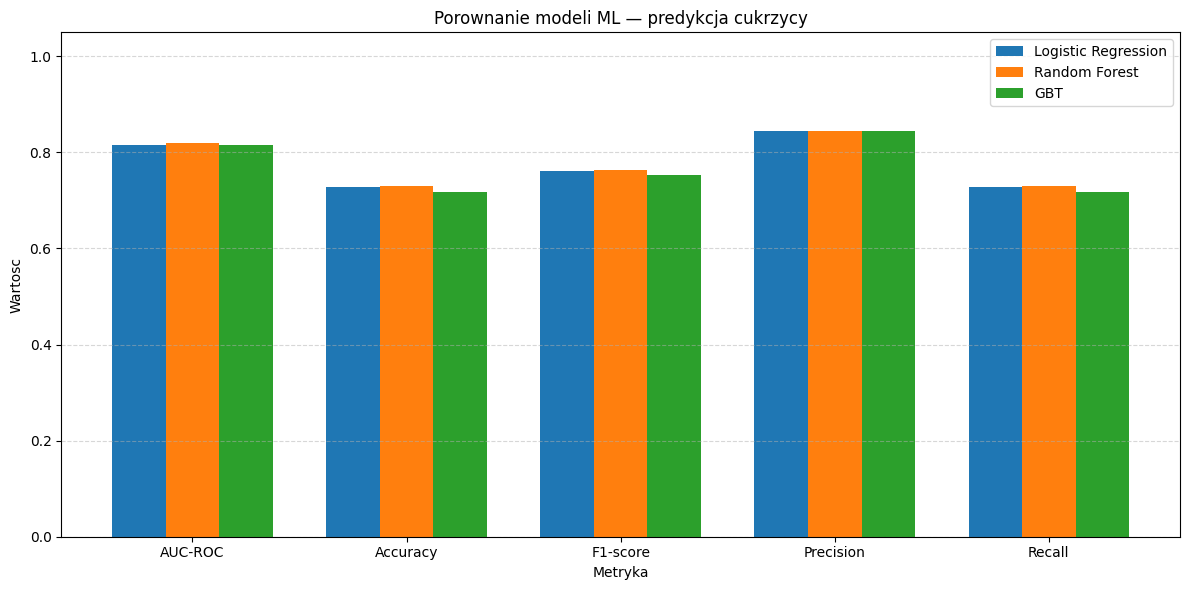

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results = {
    "Model":     ["Logistic Regression", "Random Forest", "GBT"],
    "AUC-ROC":   [auc_lr,  auc_rf,  auc_gbt],
    "Accuracy":  [acc_lr,  acc_rf,  acc_gbt],
    "F1-score":  [f1_lr,   f1_rf,   f1_gbt],
    "Precision": [prec_lr, prec_rf, prec_gbt],
    "Recall":    [rec_lr,  rec_rf,  rec_gbt],
}

results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(4).to_string())

metrics = ["AUC-ROC", "Accuracy", "F1-score", "Precision", "Recall"]
x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
for i, model in enumerate(results_df.index):
    vals = [results_df.loc[model, m] for m in metrics]
    ax.bar(x + i * width, vals, width, label=model)

ax.set_xlabel("Metryka")
ax.set_ylabel("Wartosc")
ax.set_title("Porownanie modeli ML — predykcja cukrzycy")
ax.set_xticks(x + width)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Waznosc cech — Random Forest

Random Forest pozwala wyodrebnic, ktore cechy mialy najwiekszy wplyw na predykcje. Waznosc cech obliczana jest na podstawie sredniego spadku zanieczyszczenia Gini w wezlach drzew.

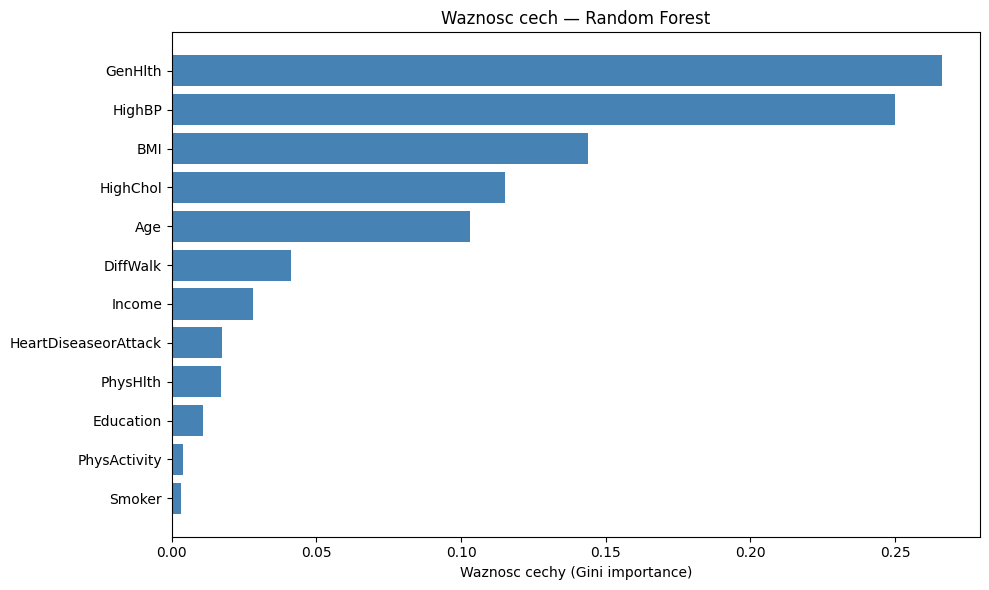


Ranking cech (od najwazniejszej):
  GenHlth                   0.2661  xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx
  HighBP                    0.2500  xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx
  BMI                       0.1440  xxxxxxxxxxxxxxxxxxxxxxxxxxxx
  HighChol                  0.1153  xxxxxxxxxxxxxxxxxxxxxxx
  Age                       0.1030  xxxxxxxxxxxxxxxxxxxx
  DiffWalk                  0.0411  xxxxxxxx
  Income                    0.0281  xxxxx
  HeartDiseaseorAttack      0.0173  xxx
  PhysHlth                  0.0171  xxx
  Education                 0.0107  xx
  PhysActivity              0.0040  
  Smoker                    0.0033  


In [24]:
rf_model = model_rf.stages[-1]
importances = rf_model.featureImportances.toArray()

feat_imp_df = pd.DataFrame({
    "Cecha": FEATURE_COLS,
    "Waznosc": importances
}).sort_values("Waznosc", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(feat_imp_df["Cecha"], feat_imp_df["Waznosc"], color="steelblue")
plt.xlabel("Waznosc cechy (Gini importance)")
plt.title("Waznosc cech — Random Forest")
plt.tight_layout()
plt.show()

print("\nRanking cech (od najwazniejszej):")
for _, row in feat_imp_df.sort_values("Waznosc", ascending=False).iterrows():
    bar = "x" * int(row["Waznosc"] * 200)
    print(f'  {row["Cecha"]:<25} {row["Waznosc"]:.4f}  {bar}')

## Macierz pomylek — najlepszy model

Macierz pomylek (confusion matrix) pokazuje jak model klasyfikuje poszczegolne przypadki. Budujemy ja recznie przy uzyciu MapReduce.

26/06/15 15:12:41 WARN DAGScheduler: Broadcasting large task binary with size 7.7 MiB
[Stage 1952:==============>                                         (1 + 3) / 4]

Macierz pomylek — Random Forest:
                       Pred. 0   Pred. 1
  Actual 0             30830     11810
  Actual 1             1954      6231

  Precision (klasa 1): 0.3454
  Recall    (klasa 1): 0.7613


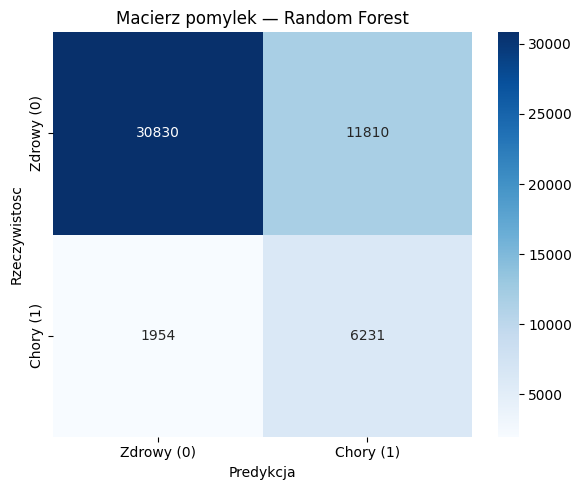

In [25]:
# Wybierz predykcje najlepszego modelu
best_pred = pred_rf

# MapReduce: budowa macierzy pomylek
# MAP: wiersz -> ((actual, predicted), 1)
# REDUCE: sumowanie
cm_rdd = best_pred.select("label", "prediction").rdd \
    .map(lambda row: ((int(row["label"]), int(row["prediction"])), 1)) \
    .reduceByKey(lambda a, b: a + b)

cm_dict = {k: v for k, v in cm_rdd.collect()}

tn = cm_dict.get((0, 0), 0)
fp = cm_dict.get((0, 1), 0)
fn = cm_dict.get((1, 0), 0)
tp = cm_dict.get((1, 1), 0)

cm_array = [[tn, fp], [fn, tp]]

print("Macierz pomylek — Random Forest:")
print(f"  {'':<20} Pred. 0   Pred. 1")
print(f"  {'Actual 0':<20} {tn:<9} {fp}")
print(f"  {'Actual 1':<20} {fn:<9} {tp}")

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
print(f"\n  Precision (klasa 1): {precision:.4f}")
print(f"  Recall    (klasa 1): {recall:.4f}")

import seaborn as sns
plt.figure(figsize=(6, 5))
sns.heatmap(cm_array, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Zdrowy (0)", "Chory (1)"],
            yticklabels=["Zdrowy (0)", "Chory (1)"])
plt.xlabel("Predykcja")
plt.ylabel("Rzeczywistosc")
plt.title("Macierz pomylek — Random Forest")
plt.tight_layout()
plt.show()

## Podsumowanie

W projekcie przeprowadzono pelny pipeline predykcji ryzyka cukrzycy z wykorzystaniem Apache Spark:

1. **Czyszczenie danych** — brak wartosci NULL, dane kompletne
2. **Klasyfikacja zmiennych** — binarne, kategoryczne, ciagla (BMI)
3. **Binaryzacja targetu** — uproszczenie do problemu binarnego (lambda + MapReduce)
4. **MapReduce** — analiza wskaznika cukrzycy per cecha oraz reczna macierz pomylek
5. **Pipeline ML** — VectorAssembler → StandardScaler → Model
6. **3 modele**: Logistic Regression, Random Forest, GBT
7. **Ewaluacja**: AUC-ROC, Accuracy, F1, Precision, Recall
8. **Feature Importance** — ranking cech wedlug Random Forest

Najwazniejszymi czynnikami ryzyka okazaly sie: `GenHlth`, `BMI`, `Age`, `HighBP` i `HighChol`.